Data section (Salwa Majeed)

Source: Chicago Data Portal, Traffic Crashes, Crashes dataset.

What we did: We downloaded 1,108,694 crash records. We removed duplicates and rows with no injury information, leaving 1,106,297. We kept crashes from 2018 onward because earlier years (2013 to 2017) have far fewer records, which suggests incomplete reporting. That left 968,596 crashes from 2018 through October 2026 (2026 is a partial year).

Cleaning: We turned UNKNOWN values into blanks, set impossible coordinates (0) to blank, and set speed limits outside 5 to 70 mph to blank. About 5.2 percent of rows are missing lighting, 6.5 percent are missing weather, 0.5 percent are missing speed limit, and 0.8 percent are missing coordinates.

New columns: severe (1 if the crash had a fatal or incapacitating injury, 0 otherwise), any_injury, hit_and_run, and crash_year. About 1.79 percent of crashes are severe.

Limits: The data has no traffic volume, so we compare severity rates and not crash counts. Freeway crashes are largely missing, and only reported crashes are included. The newest crashes may be missing later fatality updates.

In [17]:
# Salwa
import pandas as pd

RAW_PATH = "../data/raw_crashes.csv"
OUT_PATH = "../data/cleaned_crashes.csv.gz"

df = pd.read_csv(RAW_PATH, low_memory=False)
df.columns = df.columns.str.lower()
rows_raw = len(df)

first_date = str(df["crash_date"].iloc[0])
if "T" in first_date:
    date_format = "ISO8601"
else:
    date_format = "%m/%d/%Y %I:%M:%S %p"
df["crash_date"] = pd.to_datetime(df["crash_date"], format=date_format)
df["crash_year"] = df["crash_date"].dt.year

df = df.drop_duplicates(subset="crash_record_id")
df = df.replace("UNKNOWN", pd.NA)

bad_loc = (df["latitude"] == 0) | (df["longitude"] == 0)
df.loc[bad_loc, ["latitude", "longitude"]] = pd.NA

df["posted_speed_limit"] = pd.to_numeric(df["posted_speed_limit"], errors="coerce")
df.loc[~df["posted_speed_limit"].between(5, 70), "posted_speed_limit"] = pd.NA

df = df.dropna(subset=["most_severe_injury"])

for c in ["injuries_fatal", "injuries_incapacitating", "injuries_total"]:
    df[c] = df[c].fillna(0)

df["severe"] = ((df["injuries_fatal"] + df["injuries_incapacitating"]) > 0).astype(int)
df["any_injury"] = (df["injuries_total"] > 0).astype(int)
df["hit_and_run"] = (df["hit_and_run_i"] == "Y").astype(int)

rows_before_year_filter = len(df)
df = df[df["crash_year"] >= 2018].reset_index(drop=True)

print("Raw rows:", rows_raw)
print("After removing duplicates and rows with no injury info:", rows_before_year_filter)
print("After keeping 2018 onward:", len(df))
print("Share of severe crashes:", round(df["severe"].mean(), 4))
print(df["crash_year"].value_counts().sort_index())
print(df[["lighting_condition", "weather_condition", "posted_speed_limit", "latitude"]].isna().sum())

df.to_csv(OUT_PATH, index=False)
print("Saved to", OUT_PATH)

Raw rows: 1108694
After removing duplicates and rows with no injury info: 1106297
After keeping 2018 onward: 968596
Share of severe crashes: 0.0179
crash_year
2018    118728
2019    117499
2020     91860
2021    108519
2022    108119
2023    110493
2024    111805
2025    108902
2026     92671
Name: count, dtype: int64
lighting_condition    50653
weather_condition     62552
posted_speed_limit     4673
latitude               8190
dtype: int64
Saved to ../data/cleaned_crashes.csv.gz


In [18]:
from scipy.stats import chi2_contingency

def chi_test(col):
    table = pd.crosstab(df[col], df["severe"])
    chi2, p, dof, expected = chi2_contingency(table)
    n = table.to_numpy().sum()
    cramers_v = (chi2 / (n * (min(table.shape) - 1))) ** 0.5
    return chi2, p, cramers_v

for col in ["lighting_condition", "posted_speed_limit", "weather_condition"]:
    chi2, p, v = chi_test(col)
    print(col, "| chi2 =", round(chi2, 1), "| p =", p, "| Cramer's V =", round(v, 3))

lighting_condition | chi2 = 1125.0 | p = 2.8722636276054842e-242 | Cramer's V = 0.035
posted_speed_limit | chi2 = 1089.2 | p = 2.543260338333816e-202 | Cramer's V = 0.034
weather_condition | chi2 = 114.1 | p = 8.104018172414319e-20 | Cramer's V = 0.011


Stats tests (Salwa Majeed): We ran chi square tests of severity against lighting, speed limit, and weather. All three were statistically significant, but the links were weak (Cramer's V of 0.035 for lighting, 0.034 for speed limit, and 0.011 for weather). Lighting and speed limit had the strongest links, and weather had the weakest. Each factor on its own explains only a small part of severity.

In [19]:
for col in ["lighting_condition", "weather_condition", "posted_speed_limit"]:
    t = df.groupby(col)["severe"].agg(rate="mean", crashes="count")
    t["rate"] = (t["rate"] * 100).round(2)
    print(t.sort_values("rate", ascending=False), "\n")

                        rate  crashes
lighting_condition                   
DARKNESS, LIGHTED ROAD  2.70   211397
DAWN                    2.29    16061
DARKNESS                1.97    43345
DUSK                    1.92    26474
DAYLIGHT                1.57   620666 

                          rate  crashes
weather_condition                      
BLOWING SNOW              2.40      624
OTHER                     2.21     3162
RAIN                      2.16    78651
CLEAR                     1.89   758351
FOG/SMOKE/HAZE            1.78     1457
SLEET/HAIL                1.67     1081
CLOUDY/OVERCAST           1.66    28633
SEVERE CROSS WIND GATE    1.63      123
FREEZING RAIN/DRIZZLE     1.59     2573
SNOW                      1.24    31366
BLOWING SAND, SOIL, DIRT  0.00       23 

                    rate  crashes
posted_speed_limit               
33.0                9.09       11
65.0                5.56       18
26.0                4.35       23
39.0                4.26       94
40.0  

Weather results (Salwa Majeed): Severe crash rates were similar across most weather conditions (about 1.6 to 2.2 percent). Rain was slightly higher than clear weather (2.16 versus 1.89 percent), and snow was lower (1.24 percent). This is consistent with the severity part of H3, but H3 also says bad weather raises the number of crashes, which will be tested separately in the weather and forecasting analysis. Categories with fewer than about 1,000 crashes were not used for conclusions because their rates are unreliable.

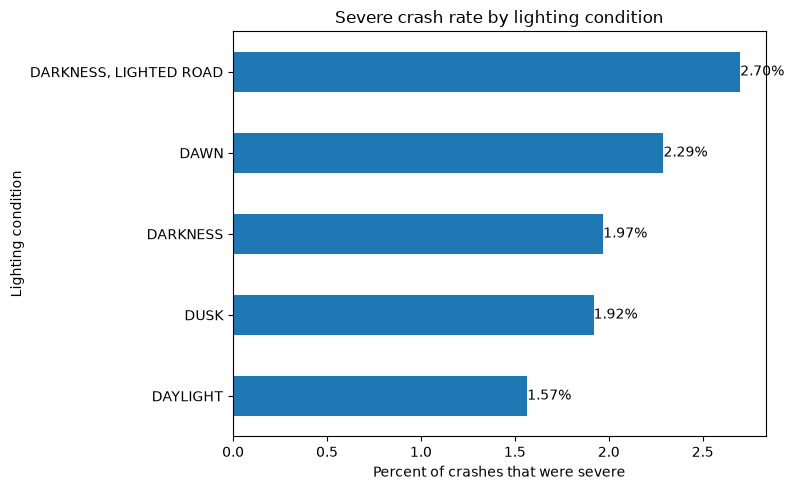

In [21]:
import matplotlib.pyplot as plt

stats = df.groupby("lighting_condition")["severe"].agg(["mean", "count"])
stats = stats[stats["count"] >= 1000]
rate = (stats["mean"] * 100).sort_values()

ax = rate.plot(kind="barh", figsize=(8, 5))
ax.bar_label(ax.containers[0], fmt="%.2f%%")
ax.set_xlabel("Percent of crashes that were severe")
ax.set_ylabel("Lighting condition")
ax.set_title("Severe crash rate by lighting condition")
plt.tight_layout()
plt.show()

Viz 1 (Salwa Majeed): Crashes in daylight were the least likely to be severe (1.57 percent). Crashes at dawn, dusk, and in darkness were all more likely to be severe. Darkness on a lighted road had the highest rate (2.70 percent), higher than darkness on an unlit road (1.97 percent). This partly supports H2. The lighted road result may mean road type or traffic speed matters too, which we can look at with our models.

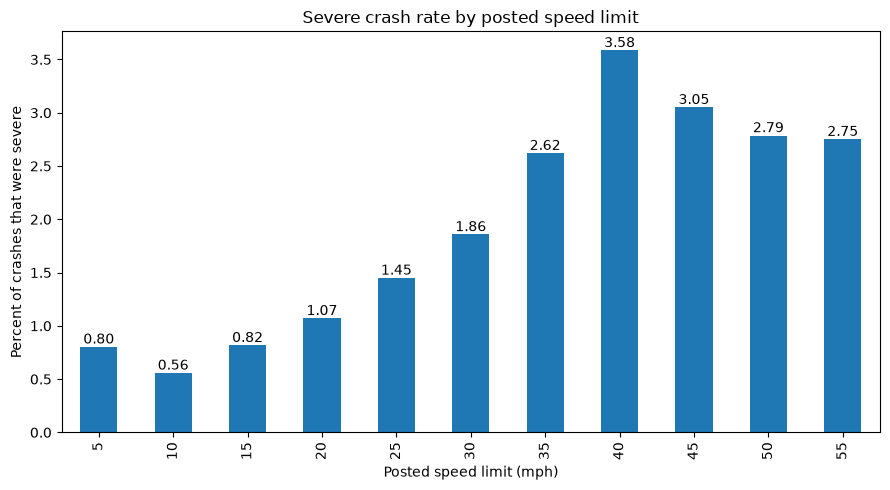

In [22]:
speed = df.groupby("posted_speed_limit")["severe"].agg(["mean", "count"])
speed = speed[speed["count"] >= 300]
speed_rate = speed["mean"] * 100
speed_rate.index = speed_rate.index.astype(int)

ax = speed_rate.plot(kind="bar", figsize=(9, 5))
ax.set_xlabel("Posted speed limit (mph)")
ax.set_ylabel("Percent of crashes that were severe")
ax.set_title("Severe crash rate by posted speed limit")
ax.bar_label(ax.containers[0], fmt="%.2f")
plt.tight_layout()
plt.show()

Viz 1b (Salwa Majeed): The severe crash rate generally rises with the posted speed limit, from about 0.6 percent at 10 mph to 1.86 percent at 30 mph and 3.58 percent at 40 mph. This supports H1, although the increase is not perfectly smooth above 40 mph. Speed limits with fewer than 300 crashes were left out because their rates are unreliable.